<a href="https://colab.research.google.com/github/rontalapoojareddy/M.T-Project/blob/main/MTech_Final_Explainable_IDS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:

# =====================================================
# FINAL M.TECH PROJECT - CELL 1
# Project Setup and Artifact Verification
# =====================================================

import os
import json
import zipfile
import shutil
import pandas as pd
import numpy as np
from google.colab import files

BASE_DIR = "/content/MTech_Final_IDS"

V2_DIR = os.path.join(BASE_DIR, "V2")
V3_DIR = os.path.join(BASE_DIR, "V3")
OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")

for folder in [V2_DIR, V3_DIR, OUTPUT_DIR]:
    os.makedirs(folder, exist_ok=True)

print("=" * 60)
print("FINAL M.TECH EXPLAINABLE INTRUSION DETECTION")
print("=" * 60)

print("\nUpload both research ZIP files:")
uploaded = files.upload()

for filename in uploaded:
    if not filename.lower().endswith(".zip"):
        continue

    if "IDS_Research_Results" in filename:
        destination = V2_DIR
    elif "MTech_IDS_V3_Final" in filename:
        destination = V3_DIR
    else:
        print("Unrecognized ZIP:", filename)
        continue

    with zipfile.ZipFile(filename) as archive:
        # Validate archive entries before extraction.
        for member in archive.infolist():
            target = os.path.abspath(
                os.path.join(destination, member.filename)
            )
            if os.path.commonpath([
                os.path.abspath(destination), target
            ]) != os.path.abspath(destination):
                raise ValueError("Unsafe ZIP entry detected")

        archive.extractall(destination)

    print("Extracted:", filename)

# Check essential artifacts
v2_model_path = os.path.join(
    V2_DIR, "research_models.joblib"
)

v3_model_path = os.path.join(
    V3_DIR,
    "MTech_IDS_V3",
    "models",
    "Oversampled_RF.joblib"
)

v3_preprocessor_path = os.path.join(
    V3_DIR,
    "MTech_IDS_V3",
    "models",
    "v3_preprocessor.joblib"
)

required = {
    "V2 research models": v2_model_path,
    "V3 oversampled model": v3_model_path,
    "V3 preprocessor": v3_preprocessor_path
}

print("\nARTIFACT VERIFICATION:")

for name, path in required.items():
    status = "PASS" if os.path.isfile(path) else "MISSING"
    print(f"{name}: {status}")

if not all(os.path.isfile(p) for p in required.values()):
    raise FileNotFoundError(
        "One or more required artifacts are missing."
    )

print("\nSUCCESS: CELL 1 COMPLETED.")
print("Both research archives are ready for integration.")


FINAL M.TECH EXPLAINABLE INTRUSION DETECTION

Upload both research ZIP files:


Saving MTech_IDS_V3_Final.zip to MTech_IDS_V3_Final.zip
Saving IDS_Research_Results.zip to IDS_Research_Results (1).zip
Extracted: MTech_IDS_V3_Final.zip
Extracted: IDS_Research_Results (1).zip

ARTIFACT VERIFICATION:
V2 research models: PASS
V3 oversampled model: PASS
V3 preprocessor: PASS

SUCCESS: CELL 1 COMPLETED.
Both research archives are ready for integration.


In [5]:

# ============================================================
# FINAL M.TECH PROJECT - CELL 2
# Inspect V2 and V3 Saved Models
# ============================================================

import os
import joblib
import pandas as pd
import sklearn

print("=" * 65)
print("FINAL IDS - MODEL COMPATIBILITY INSPECTION")
print("=" * 65)

# IMPORTANT:
# Load joblib files only from your own trusted project.

# 1. Load V2 research artifacts
print("\n[1] LOADING V2 RESEARCH ARTIFACTS")

v2_artifacts = joblib.load(v2_model_path)

print("V2 object type:", type(v2_artifacts).__name__)

if isinstance(v2_artifacts, dict):
    print("\nV2 STORED COMPONENTS:")

    for name, obj in v2_artifacts.items():
        print(
            f"  {name}: {type(obj).__name__}"
        )
else:
    print("V2 model:", type(v2_artifacts).__name__)

# 2. Load V3 preprocessing pipeline
print("\n[2] LOADING V3 PREPROCESSOR")

v3_preprocessor = joblib.load(
    v3_preprocessor_path
)

print(
    "Preprocessor type:",
    type(v3_preprocessor).__name__
)

if hasattr(v3_preprocessor, "feature_names_in_"):
    print(
        "Raw input feature count:",
        len(v3_preprocessor.feature_names_in_)
    )

    print(
        "First 10 input features:",
        list(v3_preprocessor.feature_names_in_[:10])
    )

if hasattr(v3_preprocessor, "get_feature_names_out"):
    try:
        processed_names = (
            v3_preprocessor.get_feature_names_out()
        )

        print(
            "Processed feature count:",
            len(processed_names)
        )

    except Exception as error:
        print(
            "Feature name inspection unavailable:",
            str(error)
        )

# 3. Load V3 oversampled classifier
print("\n[3] LOADING V3 OVERSAMPLED MODEL")

v3_classifier = joblib.load(v3_model_path)

print(
    "Classifier:",
    type(v3_classifier).__name__
)

if hasattr(v3_classifier, "n_features_in_"):
    print(
        "Expected processed features:",
        v3_classifier.n_features_in_
    )

if hasattr(v3_classifier, "classes_"):
    print(
        "Attack classes:",
        list(v3_classifier.classes_)
    )

# 4. Check feature compatibility
print("\n[4] FEATURE COMPATIBILITY")

try:
    preprocessor_features = len(
        v3_preprocessor.get_feature_names_out()
    )

    model_features = v3_classifier.n_features_in_

    if preprocessor_features == model_features:
        print("V3 preprocessing/model feature count: PASS")
    else:
        print("V3 preprocessing/model feature count: FAIL")
        print(
            "Preprocessor:", preprocessor_features,
            "| Model:", model_features
        )

except Exception as error:
    print("Feature compatibility check unavailable:", error)

# 5. Inspect saved V2 DNN file
print("\n[5] V2 DEEP LEARNING MODEL")

v2_dnn_path = os.path.join(V2_DIR, "dnn.keras")

print(
    "DNN file present:",
    os.path.isfile(v2_dnn_path)
)

# 6. Environment information
print("\n[6] ENVIRONMENT")

print("Scikit-learn version:", sklearn.__version__)
print("Pandas version:", pd.__version__)

print("\nSUCCESS: CELL 2 INSPECTION COMPLETED.")


FINAL IDS - MODEL COMPATIBILITY INSPECTION

[1] LOADING V2 RESEARCH ARTIFACTS
V2 object type: dict

V2 STORED COMPONENTS:
  preprocessor: ColumnTransformer
  binary_models: dict
  attack_model: RandomForestClassifier
  features: list
  best_binary: str
  ensemble_selection: dict

[2] LOADING V3 PREPROCESSOR
Preprocessor type: dict

[3] LOADING V3 OVERSAMPLED MODEL
Classifier: RandomForestClassifier
Expected processed features: 192
Attack classes: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms']

[4] FEATURE COMPATIBILITY
Feature compatibility check unavailable: 'dict' object has no attribute 'get_feature_names_out'

[5] V2 DEEP LEARNING MODEL
DNN file present: True

[6] ENVIRONMENT
Scikit-learn version: 1.6.1
Pandas version: 2.2.3

SUCCESS: CELL 2 INSPECTION COMPLETED.


In [6]:

# =====================================================
# FINAL M.TECH PROJECT - CELL 3
# Inspect V3 Preprocessing Dictionary
# =====================================================

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer

print("=" * 65)
print("FINAL IDS - V3 PREPROCESSING STRUCTURE")
print("=" * 65)

# 1. Display the dictionary structure
print("\n[1] V3 PREPROCESSOR DICTIONARY KEYS")

if not isinstance(v3_preprocessor, dict):
    raise TypeError(
        "Expected V3 preprocessing artifact to be a dictionary."
    )

for key, value in v3_preprocessor.items():
    print(f"{key}: {type(value).__name__}")

# 2. Find the actual fitted preprocessing pipeline
print("\n[2] FIND FITTED COLUMN TRANSFORMER")

candidates = [
    (key, value)
    for key, value in v3_preprocessor.items()
    if isinstance(value, ColumnTransformer)
]

if len(candidates) != 1:
    raise ValueError(
        "Expected exactly one ColumnTransformer. "
        "Please share the dictionary keys before continuing."
    )

v3_transformer_key, v3_transformer = candidates[0]

print("Transformer dictionary key:", v3_transformer_key)
print("Transformer type:", type(v3_transformer).__name__)

# 3. Inspect raw input columns
print("\n[3] RAW INPUT FEATURES")

if hasattr(v3_transformer, "feature_names_in_"):
    v3_raw_features = list(
        v3_transformer.feature_names_in_
    )

    print("Raw feature count:", len(v3_raw_features))
    print("First 10 features:", v3_raw_features[:10])
else:
    raise ValueError(
        "The V3 transformer does not expose fitted input names."
    )

# 4. Inspect processed feature count
print("\n[4] PROCESSED FEATURE COMPATIBILITY")

processed_features = (
    v3_transformer.get_feature_names_out()
)

actual_features = len(processed_features)
expected_features = v3_classifier.n_features_in_

print("Preprocessor output features:", actual_features)
print("Model expected features:", expected_features)

assert actual_features == expected_features, (
    "Feature count mismatch between V3 transformer and model."
)

print("V3 feature count compatibility: PASS")

# 5. Compare raw V2 and V3 input feature lists
print("\n[5] V2 VS V3 RAW INPUT FEATURES")

v2_raw_features = list(v2_artifacts["features"])

print("V2 raw feature count:", len(v2_raw_features))
print("V3 raw feature count:", len(v3_raw_features))

print(
    "Same feature names:",
    set(v2_raw_features) == set(v3_raw_features)
)

print(
    "Same feature order:",
    v2_raw_features == v3_raw_features
)

print("\nSUCCESS: CELL 3 COMPLETED.")


FINAL IDS - V3 PREPROCESSING STRUCTURE

[1] V3 PREPROCESSOR DICTIONARY KEYS
preprocessor: ColumnTransformer
feature_columns: list
categorical_columns: list
numerical_columns: list

[2] FIND FITTED COLUMN TRANSFORMER
Transformer dictionary key: preprocessor
Transformer type: ColumnTransformer

[3] RAW INPUT FEATURES
Raw feature count: 42
First 10 features: ['dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl']

[4] PROCESSED FEATURE COMPATIBILITY
Preprocessor output features: 192
Model expected features: 192
V3 feature count compatibility: PASS

[5] V2 VS V3 RAW INPUT FEATURES
V2 raw feature count: 42
V3 raw feature count: 42
Same feature names: True
Same feature order: True

SUCCESS: CELL 3 COMPLETED.


FINAL M.TECH EXPLAINABLE NETWORK INTRUSION DETECTION

[1/9] LOADING SAVED RESEARCH MODELS
V2 selected binary model: Random Forest
V2 binary models: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'XGBoost']
V3 attack classes: ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms']
Preprocessing feature compatibility: PASS

[2/9] LOADING OFFICIAL TEST DATA
Official test records: 82332
Raw input features: 42

[3/9] CREATING INTEGRATED PREDICTION ENGINE

[4/9] TESTING THE INTEGRATED SYSTEM
Sample size: 1000
Sample binary accuracy: 0.87
Sample binary F1: 0.8896
Prediction time: 0.6 seconds

Binary classification report:
              precision    recall  f1-score   support

      Normal       0.96      0.75      0.84       461
      Attack       0.82      0.97      0.89       539

    accuracy                           0.87      1000
   macro avg       0.89      0.86      0.87      1000
weighted avg       0.88      0.87      0.87 

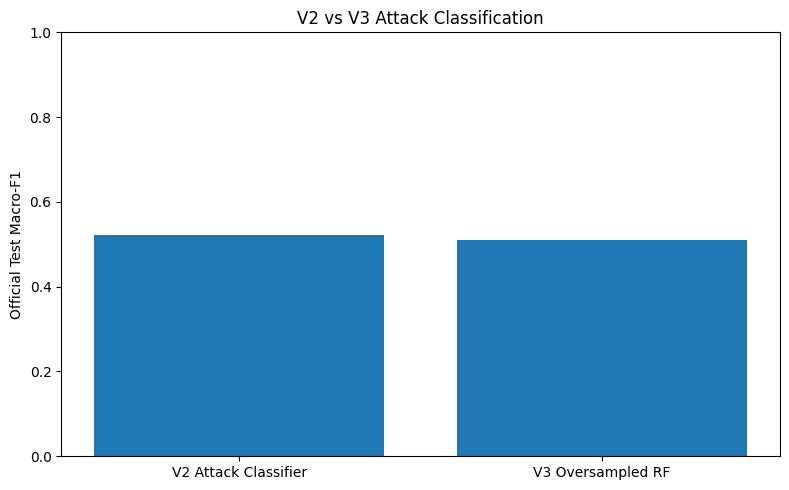

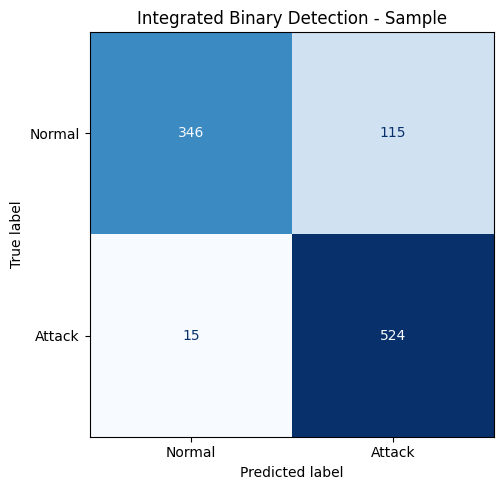


[7/9] GENERATING EXPLAINABILITY


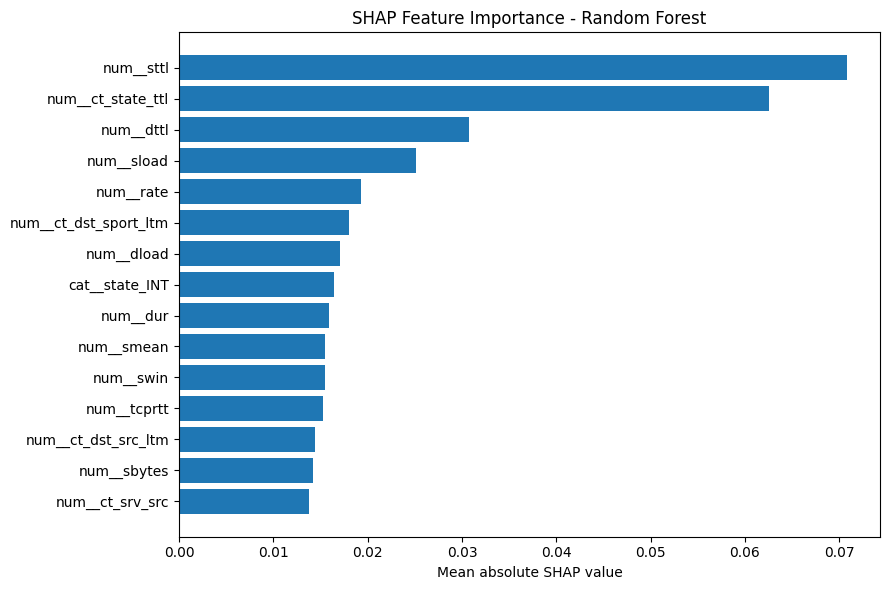

Explainability status: PASS

[8/9] SAVING FINAL PROJECT REPORT

[9/9] PREPARING INTERACTIVE DASHBOARD

Creating downloadable research package...
Research package: /content/MTech_Final_IDS/Final_IDS_Research_Outputs.zip

SUCCESS: INTEGRATED IDS INITIAL TEST COMPLETED
Starting Gradio dashboard...
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://13fbb29e0d92f9ba77.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [7]:

# ==============================================================
# FINAL M.TECH PROJECT - MASTER CELL (CELLS 4 TO 12)
# Explainable Network Intrusion Detection using V2 + V3
# No model retraining
# ==============================================================

import os, json, time, shutil, warnings, subprocess, sys
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
)

# -------------------- SETTINGS --------------------
RUN_SHAP = True
LAUNCH_DASHBOARD = True
TEST_SAMPLE_SIZE = 1000
MAX_UPLOAD_ROWS = 10000

ROOT = Path("/content/MTech_Final_IDS")
OUT = ROOT / "outputs"
OUT.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("FINAL M.TECH EXPLAINABLE NETWORK INTRUSION DETECTION")
print("=" * 65)

# -------------------- 1. LOAD MODELS --------------------
print("\n[1/9] LOADING SAVED RESEARCH MODELS")

V2 = joblib.load(ROOT / "V2/research_models.joblib")
V2_PREP = V2["preprocessor"]
V2_MODELS = V2["binary_models"]
V2_ATTACK = V2["attack_model"]
FEATURES = list(V2["features"])
BEST_BINARY = V2["best_binary"]
ENSEMBLE = V2["ensemble_selection"]

V3_BUNDLE = joblib.load(
    ROOT / "V3/MTech_IDS_V3/models/v3_preprocessor.joblib"
)
V3_PREP = V3_BUNDLE["preprocessor"]
V3_ATTACK = joblib.load(
    ROOT / "V3/MTech_IDS_V3/models/Oversampled_RF.joblib"
)

assert list(V3_PREP.feature_names_in_) == FEATURES
assert len(V3_PREP.get_feature_names_out()) == V3_ATTACK.n_features_in_

print("V2 selected binary model:", BEST_BINARY)
print("V2 binary models:", list(V2_MODELS.keys()))
print("V3 attack classes:", list(V3_ATTACK.classes_))
print("Preprocessing feature compatibility: PASS")

# DNN is loaded only if the selected binary model needs it.
DNN = None
if BEST_BINARY in ("DNN", "Hybrid Ensemble"):
    from tensorflow import keras
    DNN = keras.models.load_model(
        ROOT / "V2/dnn.keras",
        compile=False
    )

# -------------------- 2. LOAD DATA --------------------
print("\n[2/9] LOADING OFFICIAL TEST DATA")

TEST_PATH = (
    ROOT / "V3/MTech_IDS_V3/data/"
    "UNSW_NB15_testing-set.csv"
)

TEST_DF = pd.read_csv(TEST_PATH)

assert all(c in TEST_DF.columns for c in FEATURES)
assert {"label", "attack_cat"}.issubset(TEST_DF.columns)

print("Official test records:", len(TEST_DF))
print("Raw input features:", len(FEATURES))

# -------------------- 3. PREDICTION FUNCTIONS --------------------
print("\n[3/9] CREATING INTEGRATED PREDICTION ENGINE")

def dense(x):
    return x.toarray().astype("float32") if hasattr(
        x, "toarray"
    ) else np.asarray(x, dtype="float32")


def binary_probability(z):
    if BEST_BINARY == "Hybrid Ensemble":
        weights = ENSEMBLE["weights"]

        rf = V2_MODELS["Random Forest"].predict_proba(z)[:, 1]
        xgb = V2_MODELS["XGBoost"].predict_proba(z)[:, 1]
        nn = DNN.predict(dense(z), verbose=0).ravel()

        probability = (
            weights[0] * rf +
            weights[1] * xgb +
            weights[2] * nn
        )
        threshold = float(ENSEMBLE["threshold"])

    elif BEST_BINARY == "DNN":
        probability = DNN.predict(
            dense(z), verbose=0
        ).ravel()
        threshold = 0.5

    else:
        probability = V2_MODELS[
            BEST_BINARY
        ].predict_proba(z)[:, 1]
        threshold = 0.5

    return np.asarray(probability), threshold


def predict_ids(df):
    missing = [c for c in FEATURES if c not in df.columns]

    if missing:
        raise ValueError(
            "Missing required columns: " + ", ".join(missing)
        )

    x = df[FEATURES].copy()

    # V2 pipeline: binary intrusion detection
    z2 = V2_PREP.transform(x)
    probabilities, threshold = binary_probability(z2)
    is_attack = probabilities >= threshold

    # Attack classification is applied only to detected attacks.
    v2_types = np.full(len(df), "Normal", dtype=object)
    v3_types = np.full(len(df), "Normal", dtype=object)

    if is_attack.any():
        attack_rows = x.loc[is_attack]

        z2_attack = V2_PREP.transform(attack_rows)
        z3_attack = V3_PREP.transform(attack_rows)

        v2_types[is_attack] = V2_ATTACK.predict(z2_attack)
        v3_types[is_attack] = V3_ATTACK.predict(z3_attack)

    result = df.copy()

    result["Binary_Prediction"] = np.where(
        is_attack, "Attack", "Normal"
    )
    result["Attack_Probability"] = probabilities
    result["V2_Attack_Type"] = v2_types
    result["V3_Attack_Type"] = v3_types

    # Qualitative risk bands based on model probability.
    # These are presentation categories, not calibrated severity.
    result["Risk_Band"] = pd.cut(
        probabilities,
        bins=[-0.001, 0.25, 0.5, 0.75, 1.001],
        labels=["Low", "Moderate", "High", "Very High"]
    ).astype(str)

    return result


# -------------------- 4. TEST PREDICTIONS --------------------
print("\n[4/9] TESTING THE INTEGRATED SYSTEM")

sample = TEST_DF.sample(
    n=min(TEST_SAMPLE_SIZE, len(TEST_DF)),
    random_state=42
).copy()

start = time.time()
predictions = predict_ids(sample)

y_true = sample["label"].astype(int).to_numpy()
y_pred = (
    predictions["Binary_Prediction"] == "Attack"
).astype(int).to_numpy()

sample_accuracy = accuracy_score(y_true, y_pred)
sample_f1 = f1_score(y_true, y_pred, zero_division=0)

print("Sample size:", len(sample))
print("Sample binary accuracy:", round(sample_accuracy, 4))
print("Sample binary F1:", round(sample_f1, 4))
print("Prediction time:", round(time.time()-start, 2), "seconds")

print("\nBinary classification report:")
print(classification_report(
    y_true, y_pred,
    target_names=["Normal", "Attack"],
    zero_division=0
))

predictions.to_csv(
    OUT / "integrated_sample_predictions.csv",
    index=False
)

# -------------------- 5. RESEARCH COMPARISON --------------------
print("\n[5/9] COMPARING V2 AND V3 RESEARCH")

v2_report = pd.read_csv(
    ROOT / "V2/multiclass_test_report.csv",
    index_col=0
)

v3_report = pd.read_csv(
    ROOT / "V3/MTech_IDS_V3/results/"
    "v3_oversampled_test_report.csv",
    index_col=0
)

def get_macro_f1(report):
    for key in ("macro avg", "macro_avg"):
        if key in report.index:
            return float(report.loc[key, "f1-score"])
    raise ValueError("Macro F1 not found in report")

v2_macro = get_macro_f1(v2_report)
v3_macro = get_macro_f1(v3_report)

comparison = pd.DataFrame({
    "Model": [
        "V2 Attack Classifier",
        "V3 Oversampled RF"
    ],
    "Test_Macro_F1": [
        v2_macro, v3_macro
    ]
})

comparison.to_csv(
    OUT / "research_comparison.csv",
    index=False
)

print(comparison.to_string(index=False))
print(
    "\nBest reported attack-only test Macro-F1:",
    comparison.loc[
        comparison["Test_Macro_F1"].idxmax(), "Model"
    ]
)

print(
    "Note: These are saved attack-only research results, "
    "not the integrated end-to-end score."
)

# -------------------- 6. VISUALIZATIONS --------------------
print("\n[6/9] GENERATING RESEARCH GRAPHS")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    comparison["Model"],
    comparison["Test_Macro_F1"]
)
ax.set_title("V2 vs V3 Attack Classification")
ax.set_ylabel("Official Test Macro-F1")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(
    OUT / "v2_v3_comparison.png",
    dpi=160
)
plt.show()
plt.close()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    display_labels=["Normal", "Attack"],
    cmap="Blues",
    ax=ax,
    colorbar=False
)
ax.set_title("Integrated Binary Detection - Sample")
plt.tight_layout()
plt.savefig(
    OUT / "binary_confusion_matrix.png",
    dpi=160
)
plt.show()
plt.close()

# -------------------- 7. EXPLAINABILITY --------------------
print("\n[7/9] GENERATING EXPLAINABILITY")

shap_status = "Not requested"

if RUN_SHAP:
    try:
        import shap

        # Explain the actual selected binary model
        # when it is supported by TreeExplainer.
        if BEST_BINARY in V2_MODELS and BEST_BINARY in (
            "Random Forest", "Decision Tree", "XGBoost"
        ):
            explain_model = V2_MODELS[BEST_BINARY]

            explain_x = TEST_DF[FEATURES].sample(
                n=10, random_state=42
            )
            explain_z = dense(V2_PREP.transform(explain_x))

            explainer = shap.TreeExplainer(explain_model)
            values = explainer.shap_values(explain_z)

            if isinstance(values, list):
                importance = np.abs(
                    np.asarray(values[-1])
                ).mean(axis=0)
            else:
                arr = np.asarray(values)
                if arr.ndim == 3:
                    importance = np.abs(arr[:, :, -1]).mean(axis=0)
                else:
                    importance = np.abs(arr).mean(axis=0)

            names = V2_PREP.get_feature_names_out()

            top = pd.DataFrame({
                "Feature": names,
                "Mean_Absolute_SHAP": importance
            }).sort_values(
                "Mean_Absolute_SHAP",
                ascending=False
            ).head(15)

            top.to_csv(
                OUT / "shap_feature_importance.csv",
                index=False
            )

            fig, ax = plt.subplots(figsize=(9, 6))
            ax.barh(
                top["Feature"][::-1],
                top["Mean_Absolute_SHAP"][::-1]
            )
            ax.set_title(
                f"SHAP Feature Importance - {BEST_BINARY}"
            )
            ax.set_xlabel("Mean absolute SHAP value")
            plt.tight_layout()
            plt.savefig(
                OUT / "shap_importance.png",
                dpi=160
            )
            plt.show()
            plt.close()

            shap_status = "PASS"

        else:
            shap_status = (
                "Skipped: selected binary model is not "
                "supported by this TreeExplainer section"
            )

    except Exception as error:
        shap_status = "Unavailable: " + str(error)[:200]

print("Explainability status:", shap_status)

# -------------------- 8. SAVE REPORT --------------------
print("\n[8/9] SAVING FINAL PROJECT REPORT")

report = {
    "project": "Explainable Network Intrusion Detection System",
    "dataset": "UNSW-NB15",
    "training_performed_in_this_cell": False,
    "selected_binary_model": BEST_BINARY,
    "official_test_records": len(TEST_DF),
    "sample_records": len(sample),
    "sample_binary_accuracy": float(sample_accuracy),
    "sample_binary_f1": float(sample_f1),
    "v2_attack_only_test_macro_f1": v2_macro,
    "v3_attack_only_test_macro_f1": v3_macro,
    "shap_status": shap_status,
    "note": (
        "Sample results are not full official test results. "
        "Attack-only metrics are not end-to-end metrics."
    )
}

with open(OUT / "final_project_report.json", "w") as f:
    json.dump(report, f, indent=4)

# -------------------- 9. GRADIO DASHBOARD --------------------
print("\n[9/9] PREPARING INTERACTIVE DASHBOARD")

if LAUNCH_DASHBOARD:
    try:
        import gradio as gr
    except ImportError:
        subprocess.check_call([
            sys.executable, "-m", "pip",
            "-q", "install", "gradio"
        ])
        import gradio as gr

    def analyze_csv(file_path):
        if file_path is None:
            raise gr.Error("Please upload a CSV file.")

        data = pd.read_csv(file_path)

        if len(data) == 0:
            raise gr.Error("The CSV is empty.")

        if len(data) > MAX_UPLOAD_ROWS:
            raise gr.Error(
                f"Maximum {MAX_UPLOAD_ROWS} records per upload."
            )

        result = predict_ids(data)

        total = len(result)
        attacks = int(
            (result["Binary_Prediction"] == "Attack").sum()
        )
        normal = total - attacks

        summary = pd.DataFrame({
            "Metric": [
                "Total Records",
                "Predicted Attacks",
                "Predicted Normal",
                "Attack Percentage"
            ],
            "Value": [
                total,
                attacks,
                normal,
                round(attacks / total * 100, 2)
            ]
        })

        output_file = OUT / "latest_uploaded_predictions.csv"
        result.to_csv(output_file, index=False)

        return (
            summary,
            result.head(100),
            str(output_file)
        )

    with gr.Blocks(
        title="M.Tech Explainable IDS"
    ) as dashboard:

        gr.Markdown(
            "# Network Intrusion Detection System\n"
            "### UNSW-NB15 | Machine Learning | Explainable AI\n"
            "Upload a CSV with the 42 required network features."
        )

        file_input = gr.File(
            label="Upload Network Traffic CSV",
            file_types=[".csv"],
            type="filepath"
        )

        analyze_button = gr.Button(
            "Analyze Network Traffic",
            variant="primary"
        )

        summary_output = gr.Dataframe(
            label="Detection Summary"
        )

        predictions_output = gr.Dataframe(
            label="Prediction Preview (First 100 Records)"
        )

        download_output = gr.File(
            label="Download Complete Predictions"
        )

        analyze_button.click(
            fn=analyze_csv,
            inputs=file_input,
            outputs=[
                summary_output,
                predictions_output,
                download_output
            ]
        )

        gr.Markdown(
            "**Research note:** The dashboard compares V2 and V3 "
            "attack-type predictions after V2 binary detection. "
            "Risk bands represent probability ranges, not "
            "validated clinical or operational severity."
        )

    print("\nCreating downloadable research package...")

    archive_path = shutil.make_archive(
        str(ROOT / "Final_IDS_Research_Outputs"),
        "zip",
        root_dir=str(OUT)
    )

    print("Research package:", archive_path)
    print("\nSUCCESS: INTEGRATED IDS INITIAL TEST COMPLETED")
    print("Starting Gradio dashboard...")

    dashboard.launch(
        share=True,
        debug=False,
        show_error=True
    )

else:
    archive_path = shutil.make_archive(
        str(ROOT / "Final_IDS_Research_Outputs"),
        "zip",
        root_dir=str(OUT)
    )

    print("\nSUCCESS: MASTER CELL COMPLETED")
    print("Results:", archive_path)
